# Proyek Analisis Data: E-Commerce Public Dataset
- **Nama:** Reynard Radithya Aydin
- **Email:** reynard.aydin@gmail.com
- **ID Dicoding:** reynard_aydinzp6o

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Kategori produk apa yang menghasilkan kuantitas pesanan terbanyak dan total pendapatan (revenue) tertinggi sepanjang tahun 2017 hingga 2018, sebagai dasar penentuan fokus stok dan promosi?

- **Pertanyaan 2:** Bagaimana perbandingan rata-rata skor review antara pesanan yang dikirim tepat waktu dan yang terlambat pada tahun 2017 hingga 2018, sebagai dasar evaluasi kinerja mitra logistik?

- **Pertanyaan 3:** Bagaimana profil segmentasi pelanggan berdasarkan Recency, Frequency, dan Monetary (RFM) sepanjang tahun 2017 hingga 2018, sebagai dasar perancangan program retensi pelanggan?

- **Pertanyaan 4:** Di negara bagian (state) mana saja konsentrasi pelanggan dan total transaksi terbesar di Brasil pada tahun 2017 hingga 2018, sebagai dasar penentuan prioritas ekspansi logistik?

## Import Semua Packages/Library yang Digunakan

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# Visual style setup
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

## Data Wrangling

### Gathering Data
Memuat seluruh file dataset dari folder `data/` ke dalam DataFrame.

In [2]:
data_dir = 'data'

customers_df = pd.read_csv(os.path.join(data_dir, 'customers_dataset.csv'))
orders_df = pd.read_csv(os.path.join(data_dir, 'orders_dataset.csv'))
order_items_df = pd.read_csv(os.path.join(data_dir, 'order_items_dataset.csv'))
order_payments_df = pd.read_csv(os.path.join(data_dir, 'order_payments_dataset.csv'))
order_reviews_df = pd.read_csv(os.path.join(data_dir, 'order_reviews_dataset.csv'))
products_df = pd.read_csv(os.path.join(data_dir, 'products_dataset.csv'))
category_trans_df = pd.read_csv(os.path.join(data_dir, 'product_category_name_translation.csv'))
sellers_df = pd.read_csv(os.path.join(data_dir, 'sellers_dataset.csv'))
geolocation_df = pd.read_csv(os.path.join(data_dir, 'geolocation_dataset.csv'))

print('Dataset shapes:')
print('- orders_df:', orders_df.shape)
print('- customers_df:', customers_df.shape)
print('- order_items_df:', order_items_df.shape)
print('- products_df:', products_df.shape)
print('- order_reviews_df:', order_reviews_df.shape)

Dataset shapes:
- orders_df: (99441, 8)
- customers_df: (99441, 5)
- order_items_df: (112650, 7)
- products_df: (32951, 9)
- order_reviews_df: (99224, 7)


In [3]:
orders_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
order_items_df.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


**Insight:**
- Dataset terdiri dari 9 tabel yang saling terhubung melalui kolom kunci seperti `order_id`, `customer_id`, dan `product_id`.
- Tabel utama `orders_df` memiliki 99,441 baris, sementara `order_items_df` memiliki 112,650 baris (karena satu pesanan bisa memiliki lebih dari satu item).

### Assessing Data
Memeriksa kualitas data untuk menemukan missing values, inkonsistensi tipe data, dan duplikasi.

In [5]:
# Cek struktur dan missing values pada orders_df
orders_df.info()
print('\nMissing values orders_df:')
print(orders_df.isna().sum())
print('\nDuplikat orders_df:', orders_df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB

Missing values orders_df:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_d

In [6]:
# Cek penyebab missing order_delivered_customer_date per order_status
print('Missing order_delivered_customer_date per order_status:')
print(orders_df[orders_df['order_delivered_customer_date'].isna()]['order_status'].value_counts())
print('\nMissing order_approved_at:', orders_df['order_approved_at'].isna().sum())
print('Missing order_delivered_carrier_date:', orders_df['order_delivered_carrier_date'].isna().sum())

Missing order_delivered_customer_date per order_status:


order_status
shipped        1107
canceled        619
unavailable     609
invoiced        314
processing      301
delivered         8
created           5
approved          2
Name: count, dtype: int64

Missing order_approved_at: 160
Missing order_delivered_carrier_date: 1783


In [7]:
# Cek order items
print('Missing items total:', order_items_df.isna().sum().sum())
print('Duplikat items:', order_items_df.duplicated().sum())
order_items_df[['price', 'freight_value']].describe()

Missing items total: 0


Duplikat items: 0


,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [8]:
# Cek kategori produk
print('Missing product_category_name:', products_df['product_category_name'].isna().sum())

Missing product_category_name: 610


In [9]:
# Cek review: missing, duplikasi review_id, dan duplikasi order_id
print('Missing review_comment_message:', order_reviews_df['review_comment_message'].isna().sum())
print('Duplikat review_id:', order_reviews_df['review_id'].duplicated().sum())
print('\nDuplikat order_id di review (satu order punya >1 review):')
print('Jumlah:', order_reviews_df['order_id'].duplicated().sum())
print('\nDuplikat customer_id:', customers_df['customer_id'].duplicated().sum())

Missing review_comment_message: 58247
Duplikat review_id: 814

Duplikat order_id di review (satu order punya >1 review):
Jumlah: 551

Duplikat customer_id: 0


**Steps to Take:**
- Konversi kolom tanggal dari `object` ke `datetime64`.
- Filter pesanan `delivered` saja untuk mengatasi missing values kolom pengiriman.
- Merge tabel translasi kategori dan isi nama kategori kosong dengan `'others'`.
- Deduplikasi review per `order_id`.
- Setelah merge ke master table, cek dan isi `review_score` null dengan median.

#### Rangkuman Masalah Data yang Ditemukan:

| No | Permasalahan | Detail | Solusi (Cleaning) |
|---|---|---|---|
| 1 | **Tipe Data** | Kolom tanggal pada `orders_df` masih bertipe `object` (string). | Konversi ke `datetime64` menggunakan `pd.to_datetime()`. |
| 2 | **Missing Values Pengiriman** | `order_delivered_customer_date` memiliki nilai kosong — dari pengecekan per `order_status`, seluruh missing value berada pada pesanan berstatus selain `delivered` (shipped (1107), canceled (619), unavailable (609), invoiced (314), processing (301), delivered (8), created (5), approved (2)). Kolom `order_approved_at` (160 missing) dan `order_delivered_carrier_date` (1783 missing) juga terdampak. | Filter hanya pesanan berstatus `delivered` untuk analisis. |
| 3 | **Kategori Produk** | 610 produk tanpa nama kategori, dan kategori masih dalam Bahasa Portugis. | Merge dengan tabel translasi, isi nilai kosong dengan `'others'`. |
| 4 | **Duplikasi Review** | Terdapat duplikat `review_id` (814 baris) dan duplikat `order_id` di tabel review (551 baris), yang berarti satu pesanan memiliki lebih dari satu entri review. | Deduplikasi per `order_id` menggunakan `drop_duplicates(subset=['order_id'])`. |
| 5 | **Review Score Null Pasca-Merge** | Setelah merge seluruh tabel, beberapa order tidak memiliki `review_score` karena tidak ada review yang cocok. | Isi nilai null dengan median `review_score`. Jumlah null akan dicek sebelum pengisian. |

**Insight:**
- Tipe data kolom tanggal perlu dikonversi agar bisa dihitung durasi pengiriman.
- Missing value pada kolom pengiriman (`order_delivered_customer_date`) terjadi pada pesanan berstatus selain `delivered` (shipped (1107), canceled (619), unavailable (609), invoiced (314), processing (301), delivered (8), created (5), approved (2)), sehingga filtering ke status `delivered` adalah solusi yang tepat.
- Kolom `order_approved_at` (160 missing) dan `order_delivered_carrier_date` (1783 missing) juga akan tertangani oleh filter ini.
- Kategori produk memiliki 610 nilai kosong yang perlu diisi, dan perlu diterjemahkan ke Bahasa Inggris.
- Duplikasi review per `order_id` (551 baris) perlu ditangani agar setiap order hanya diwakili oleh satu skor review.

### Cleaning Data
Menangani seluruh permasalahan yang ditemukan di tahap Assessing Data.

In [10]:
# Fixing: Konversi kolom tanggal ke datetime (Masalah 1)
date_columns = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]
for col in date_columns:
    orders_df[col] = pd.to_datetime(orders_df[col])

orders_df[date_columns].dtypes

order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object

In [11]:
# Fixing: Filter pesanan delivered dan hitung delivery metrics (Masalah 2)
orders_delivered_df = orders_df[orders_df['order_status'] == 'delivered'].copy()

# Hitung durasi kirim dan delay (dalam hari)
orders_delivered_df['delivery_duration_days'] = (
    orders_delivered_df['order_delivered_customer_date'] - orders_delivered_df['order_purchase_timestamp']
).dt.days

orders_delivered_df['delay_days'] = (
    orders_delivered_df['order_delivered_customer_date'] - orders_delivered_df['order_estimated_delivery_date']
).dt.days

# Klasifikasi ketepatan waktu pengiriman
orders_delivered_df['delivery_status'] = orders_delivered_df['delay_days'].apply(
    lambda x: 'Delayed' if x > 0 else 'On Time'
)

print('Jumlah pesanan delivered:', len(orders_delivered_df))
print('\nDistribusi pengiriman:')
print(orders_delivered_df['delivery_status'].value_counts())

Jumlah pesanan delivered: 96478

Distribusi pengiriman:
delivery_status
On Time    89944
Delayed     6534
Name: count, dtype: int64


In [12]:
# Fixing: Translate nama kategori dan isi yang kosong (Masalah 3)
products_clean_df = products_df.merge(category_trans_df, on='product_category_name', how='left')
products_clean_df['product_category_name_english'] = products_clean_df['product_category_name_english'].fillna('others')

print('Sisa missing category:', products_clean_df['product_category_name_english'].isna().sum())

Sisa missing category: 0


In [13]:
# Fixing: Deduplikasi review per order_id (Masalah 4)
reviews_clean_df = order_reviews_df[['order_id', 'review_score']].drop_duplicates(subset=['order_id'])
print('Total review unik:', len(reviews_clean_df))

Total review unik: 98673


In [14]:
# Merge seluruh tabel bersih ke master table - all_df (Masalah 5)
all_df = orders_delivered_df.merge(customers_df, on='customer_id', how='inner')
all_df = all_df.merge(order_items_df, on='order_id', how='inner')
all_df = all_df.merge(products_clean_df[['product_id', 'product_category_name_english']], on='product_id', how='left')
all_df = all_df.merge(reviews_clean_df, on='order_id', how='left')

# Fixing: Cek dan isi review_score null setelah merge
print('Jumlah review_score null setelah merge:', all_df['review_score'].isna().sum())

# Isi review_score null dengan median
all_df['review_score'] = all_df['review_score'].fillna(all_df['review_score'].median())

print('Dimensi all_df:', all_df.shape)
print('\nVerifikasi: cek missing value setelah cleaning:')
print(all_df[['order_id', 'customer_unique_id', 'product_category_name_english', 'price', 'review_score', 'delivery_status']].isna().sum())

Jumlah review_score null setelah merge: 827
Dimensi all_df: (110197, 23)

Verifikasi: cek missing value setelah cleaning:
order_id                         0
customer_unique_id               0
product_category_name_english    0
price                            0
review_score                     0
delivery_status                  0
dtype: int64


In [15]:
all_df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_duration_days,delay_days,...,customer_city,customer_state,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name_english,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,8.0,-8.0,...,sao paulo,SP,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,housewares,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,13.0,-6.0,...,barreiras,BA,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumery,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,9.0,-18.0,...,vianopolis,GO,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,auto,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,13.0,-13.0,...,sao goncalo do amarante,RN,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,2.0,-10.0,...,santo andre,SP,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,stationery,5.0


**Insight:**
- Konversi tipe data tanggal berhasil, seluruh 5 kolom tanggal kini bertipe `datetime64`.
- Filter `delivered` mempertahankan 96,478 pesanan yang benar-benar sampai ke pelanggan.
- Translasi kategori produk selesai tanpa sisa missing value.
- Deduplikasi review per `order_id` menghasilkan 98,673 review unik.
- Setelah merge, 827 baris `review_score` null diisi dengan median. Pengecekan ulang mengonfirmasi seluruh kolom kunci bebas null.
- Tabel master `all_df` berdimensi 110,197 baris × 23 kolom, siap untuk tahap analisis selanjutnya.

## Exploratory Data Analysis (EDA)

Eksplorasi data untuk menjawab pertanyaan bisnis. Data difilter sesuai periode pertanyaan (tahun 2017-2018).

In [16]:
# Filter data sesuai periode pertanyaan bisnis (2017-2018)
df_filtered = all_df[all_df['order_purchase_timestamp'].dt.year.isin([2017, 2018])].copy()
print('Jumlah baris setelah filter 2017-2018:', len(df_filtered))

Jumlah baris setelah filter 2017-2018: 109880


### Explore Pertanyaan 1: Performa Kategori Produk

In [17]:
# Performa kategori produk (2017-2018)
category_summary = df_filtered.groupby('product_category_name_english').agg(
    total_orders=('order_id', 'count'),
    total_revenue=('price', 'sum'),
    avg_price=('price', 'mean')
).reset_index()

# Top 5 Kuantitas
top5_volume = category_summary.sort_values(by='total_orders', ascending=False).head(5)
print('Top 5 Kategori (Kuantitas):')
print(top5_volume[['product_category_name_english', 'total_orders', 'total_revenue']].to_string(index=False))

# Top 5 Revenue
top5_revenue = category_summary.sort_values(by='total_revenue', ascending=False).head(5)
print('\nTop 5 Kategori (Revenue):')
print(top5_revenue[['product_category_name_english', 'total_revenue', 'total_orders']].to_string(index=False))

Top 5 Kategori (Kuantitas):
product_category_name_english  total_orders  total_revenue
               bed_bath_table         10945     1022955.77
                health_beauty          9422     1229557.50
               sports_leisure          8414      952840.40
              furniture_decor          8095      706237.17
        computers_accessories          7632      888055.59

Top 5 Kategori (Revenue):
product_category_name_english  total_revenue  total_orders
                health_beauty     1229557.50          9422
                watches_gifts     1163465.91          5855
               bed_bath_table     1022955.77         10945
               sports_leisure      952840.40          8414
        computers_accessories      888055.59          7632


**Insight:**
- Kategori **bed_bath_table** memiliki kuantitas pesanan terbanyak (10,945 pesanan), diikuti **health_beauty** (9,422) dan **sports_leisure** (8,414).
- Dari sisi revenue, **health_beauty** menghasilkan pendapatan tertinggi (R$ 1,229,557.50), diikuti **watches_gifts** (R$ 1,163,465.91) dan **bed_bath_table** (R$ 1,022,955.77).
- Terdapat perbedaan antara kategori dengan kuantitas terbanyak dan revenue tertinggi, menunjukkan adanya variasi harga rata-rata per item antar kategori.

### Explore Pertanyaan 2: Pengiriman dan Kepuasan Pelanggan

In [18]:
# Rata-rata review berdasarkan ketepatan waktu kirim (2017-2018)
delivery_review_summary = df_filtered.groupby('delivery_status').agg(
    total_orders=('order_id', 'nunique'),
    avg_review_score=('review_score', 'mean'),
    median_review_score=('review_score', 'median'),
    pct_rating_1=('review_score', lambda x: (x == 1).mean() * 100),
    pct_rating_5=('review_score', lambda x: (x == 5).mean() * 100)
).reset_index()

delivery_review_summary

,delivery_status,total_orders,avg_review_score,median_review_score,pct_rating_1,pct_rating_5
0,Delayed,6531,2.325940,1.0,53.037608,18.638931
1,On Time,89680,4.214722,5.0,8.353066,60.678614


**Insight:**
- Pesanan **On Time** memiliki rata-rata skor review 4.21, jauh lebih tinggi dibandingkan pesanan **Delayed** yang hanya 2.33.
- Proporsi rating bintang 5 pada pengiriman On Time mencapai 60.68%, sementara pada pengiriman Delayed hanya 18.64%.
- Sebaliknya, proporsi rating bintang 1 pada pengiriman Delayed adalah 53.04%, jauh lebih tinggi daripada On Time (8.35%).
- Data ini menunjukkan bahwa ketepatan waktu pengiriman berkaitan erat dengan tingkat kepuasan pelanggan.

### Explore Pertanyaan 3: Profil RFM Pelanggan

In [19]:
# Kalkulasi RFM per pelanggan (2017-2018)
recent_date = df_filtered['order_purchase_timestamp'].max() + pd.Timedelta(days=1)

rfm_df = df_filtered.groupby('customer_unique_id').agg({
    'order_purchase_timestamp': lambda x: (recent_date - x.max()).days,
    'order_id': 'nunique',
    'price': 'sum'
}).reset_index()

rfm_df.columns = ['customer_unique_id', 'recency', 'frequency', 'monetary']

print('Ringkasan statistik RFM:')
print(rfm_df[['recency', 'frequency', 'monetary']].describe())

Ringkasan statistik RFM:
            recency     frequency      monetary
count  93104.000000  93104.000000  93104.000000
mean     236.702924      1.033371    141.573156
std      150.942219      0.209012    215.760366
min        1.000000      1.000000      0.850000
25%      114.000000      1.000000     47.650000
50%      218.000000      1.000000     89.700000
75%      345.000000      1.000000    154.175000
max      602.000000     15.000000  13440.000000


**Insight:**
- Dari 93,104 pelanggan unik, rata-rata recency adalah 236.70 hari (median 218 hari), artinya sebagian besar pelanggan sudah cukup lama tidak bertransaksi.
- Rata-rata frequency hanya 1.03 transaksi per pelanggan (maksimum 15), menunjukkan bahwa sebagian besar pelanggan (97.0%) hanya melakukan satu kali pembelian.
- Rata-rata monetary adalah R$ 141.57 per pelanggan (median R$ 89.70), dengan pelanggan teratas mencapai R$ 13,440.00.
- Distribusi monetary yang sangat skewed menunjukkan bahwa sebagian kecil pelanggan berkontribusi pada total belanja yang jauh lebih besar.

### Explore Pertanyaan 4: Sebaran Pelanggan per Negara Bagian

In [20]:
# Sebaran pelanggan per negara bagian (2017-2018)
geo_summary = df_filtered.groupby('customer_state').agg(
    total_customers=('customer_unique_id', 'nunique'),
    total_orders=('order_id', 'nunique'),
    total_revenue=('price', 'sum')
).reset_index().sort_values(by='total_customers', ascending=False)

print('Top 10 Negara Bagian:')
print(geo_summary.head(10).to_string(index=False))

# Hitung persentase pelanggan SP dan top 3
total_cust = geo_summary['total_customers'].sum()
top3_cust = geo_summary.head(3)['total_customers'].sum()
sp_cust = geo_summary[geo_summary['customer_state'] == 'SP']['total_customers'].values[0]
print(f'\nPersentase pelanggan SP: {sp_cust/total_cust*100:.1f}%')
print(f'Persentase top 3 (SP+RJ+MG): {top3_cust/total_cust*100:.1f}%')

Top 10 Negara Bagian:
customer_state  total_customers  total_orders  total_revenue
            SP            39065         40406     5055587.13
            RJ            11879         12310     1751433.85
            MG            10969         11319     1548206.88
            RS             5151          5328      726373.92
            PR             4750          4903      664048.00
            SC             3441          3537      504774.07
            BA             3155          3253      493339.26
            DF             2013          2074      295454.64
            ES             1925          1992      267783.66
            GO             1889          1950      281932.21

Persentase pelanggan SP: 41.9%
Persentase top 3 (SP+RJ+MG): 66.5%


**Insight:**
- São Paulo (SP) mendominasi dengan 39,065 pelanggan unik (41.9% dari total), 40,406 pesanan, dan total revenue R$ 5,055,587.13.
- Tiga negara bagian teratas (SP, RJ, MG) menguasai 66.5% dari total pelanggan.
- Rio de Janeiro (RJ) berada di posisi kedua dengan 11,879 pelanggan dan revenue R$ 1,751,433.85, diikuti Minas Gerais (MG) dengan 10,969 pelanggan.
- Konsentrasi yang tinggi di beberapa negara bagian menunjukkan potensi fokus ekspansi logistik di wilayah tersebut.

## Visualization & Explanatory Analysis

### Pertanyaan 1:

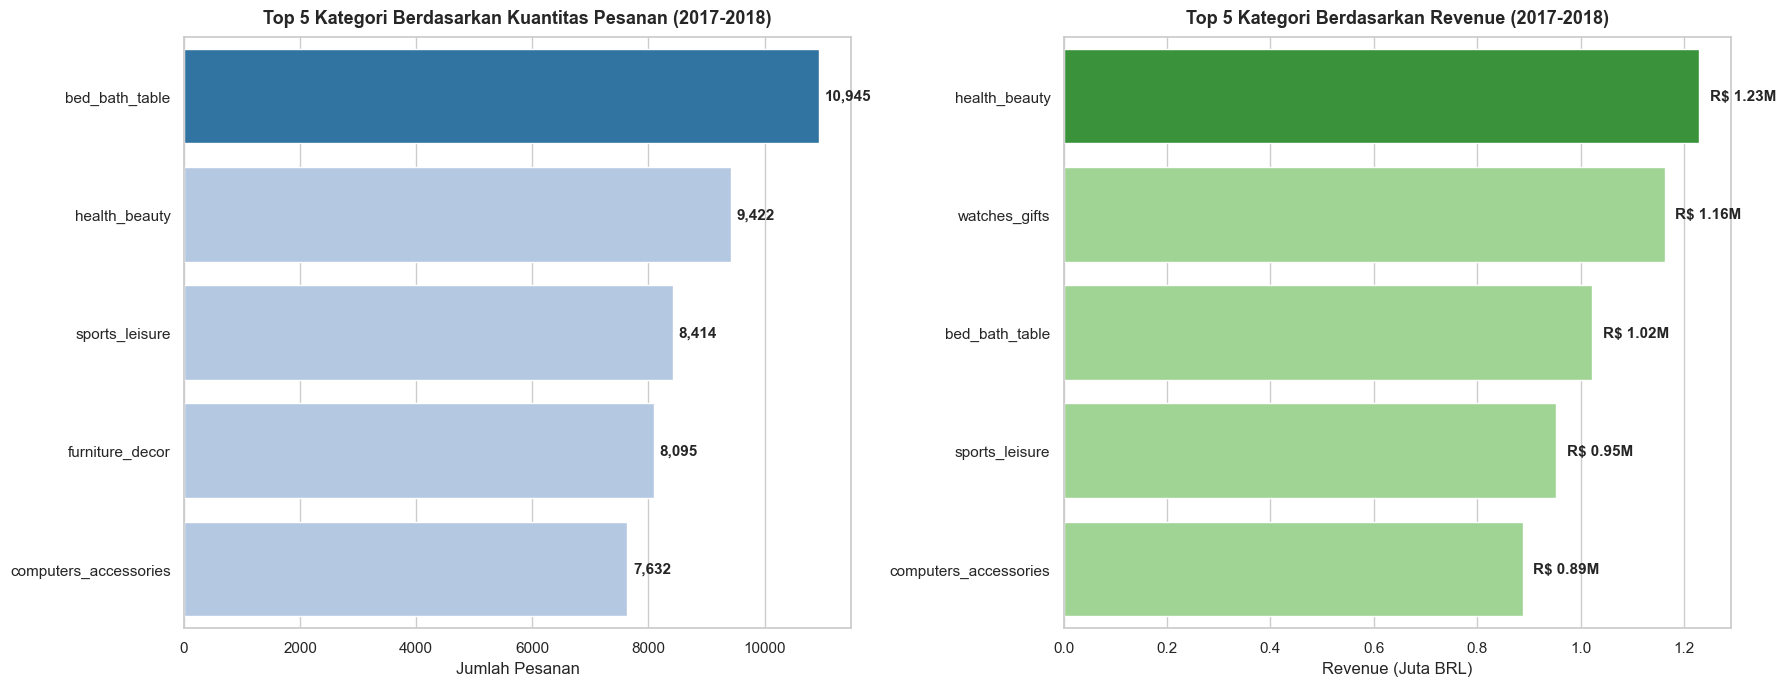

In [21]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))

# 1. Volume Terjual
top_qty = df_filtered['product_category_name_english'].value_counts().head(5)
colors_qty = ['#1f77b4' if i == 0 else '#aec7e8' for i in range(5)]
sns.barplot(x=top_qty.values, y=top_qty.index, palette=colors_qty, ax=axes[0])
axes[0].set_title('Top 5 Kategori Berdasarkan Kuantitas Pesanan (2017-2018)', fontsize=13, fontweight='bold', pad=10)
axes[0].set_xlabel('Jumlah Pesanan')
axes[0].set_ylabel('')

for i, v in enumerate(top_qty.values):
    axes[0].text(v + 100, i, f'{v:,}', va='center', fontweight='bold')

# 2. Total Revenue
top_rev = df_filtered.groupby('product_category_name_english')['price'].sum().sort_values(ascending=False).head(5)
colors_rev = ['#2ca02c' if i == 0 else '#98df8a' for i in range(5)]
sns.barplot(x=top_rev.values / 1e6, y=top_rev.index, palette=colors_rev, ax=axes[1])
axes[1].set_title('Top 5 Kategori Berdasarkan Revenue (2017-2018)', fontsize=13, fontweight='bold', pad=10)
axes[1].set_xlabel('Revenue (Juta BRL)')
axes[1].set_ylabel('')

for i, v in enumerate(top_rev.values / 1e6):
    axes[1].text(v + 0.02, i, f'R$ {v:.2f}M', va='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- Visualisasi mempertegas bahwa **bed_bath_table** memimpin dari sisi kuantitas pesanan (10,945), sedangkan **health_beauty** memimpin dari sisi total revenue (R$ 1,229,557.50).
- Perbedaan peringkat ini mengindikasikan bahwa kategori dengan volume tinggi belum tentu menghasilkan revenue tertinggi, karena perbedaan harga rata-rata per item.
- Informasi ini berguna sebagai dasar penentuan fokus stok (kategori volume tinggi) dan promosi (kategori revenue tinggi).

### Pertanyaan 2:

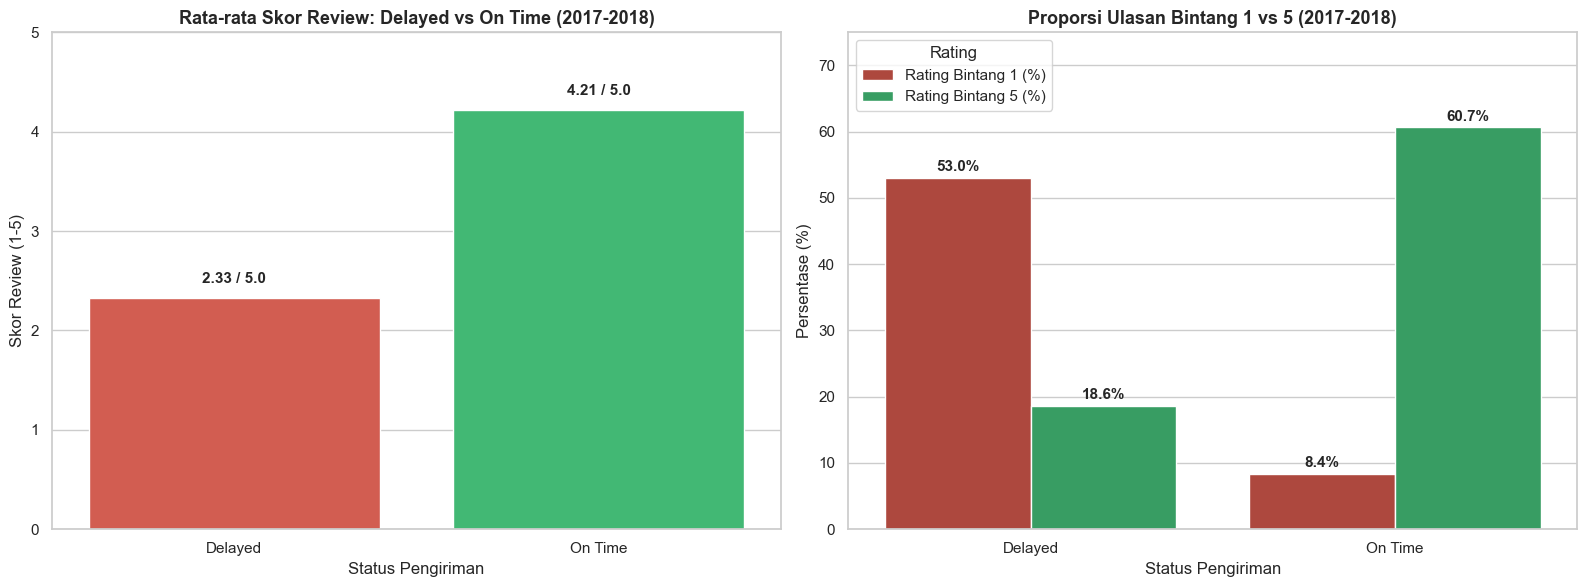

In [22]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

# 1. Rata-rata Skor Review
sns.barplot(
    data=delivery_review_summary,
    x='delivery_status',
    y='avg_review_score',
    palette=['#e74c3c', '#2ecc71'],
    ax=axes[0]
)
axes[0].set_title('Rata-rata Skor Review: Delayed vs On Time (2017-2018)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Status Pengiriman')
axes[0].set_ylabel('Skor Review (1-5)')
axes[0].set_ylim(0, 5)

for i, row in delivery_review_summary.iterrows():
    axes[0].text(i, row['avg_review_score'] + 0.15, f"{row['avg_review_score']:.2f} / 5.0", ha='center', fontweight='bold')

# 2. Persentase Bintang 1 vs Bintang 5
review_pct_df = pd.DataFrame({
    'Status': ['Delayed', 'On Time'],
    'Rating Bintang 1 (%)': [delivery_review_summary.loc[delivery_review_summary['delivery_status']=='Delayed', 'pct_rating_1'].values[0],
                             delivery_review_summary.loc[delivery_review_summary['delivery_status']=='On Time', 'pct_rating_1'].values[0]],
    'Rating Bintang 5 (%)': [delivery_review_summary.loc[delivery_review_summary['delivery_status']=='Delayed', 'pct_rating_5'].values[0],
                             delivery_review_summary.loc[delivery_review_summary['delivery_status']=='On Time', 'pct_rating_5'].values[0]]
})

review_pct_melted = review_pct_df.melt(id_vars='Status', var_name='Rating', value_name='Persentase')
sns.barplot(data=review_pct_melted, x='Status', y='Persentase', hue='Rating', palette=['#c0392b', '#27ae60'], ax=axes[1])
axes[1].set_title('Proporsi Ulasan Bintang 1 vs 5 (2017-2018)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Status Pengiriman')
axes[1].set_ylabel('Persentase (%)')
axes[1].set_ylim(0, 75)

for p in axes[1].patches:
    h = p.get_height()
    if h > 0:
        axes[1].annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h + 1), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

**Insight:**
- Grafik menunjukkan perbedaan yang jelas: pesanan On Time mendapat rata-rata skor 4.21, hampir dua kali lipat dari pesanan Delayed (2.33).
- Proporsi bintang 5 pada pengiriman On Time (60.7%) jauh melampaui pengiriman Delayed (18.6%), dan sebaliknya proporsi bintang 1 pada pengiriman Delayed (53.0%) jauh lebih tinggi daripada On Time (8.4%).
- Temuan ini menjadi dasar evaluasi kinerja mitra logistik: keterlambatan pengiriman berkaitan erat dengan rendahnya kepuasan pelanggan.

## Analisis Lanjutan (Opsional)

### Pertanyaan 3: RFM Analysis (Recency, Frequency, Monetary)
Tujuan: mengelompokkan pelanggan berdasarkan perilaku pembelian mereka tanpa menggunakan algoritma machine learning. Recency mengukur hari sejak pembelian terakhir, Frequency menghitung jumlah order, dan Monetary menghitung total belanja.

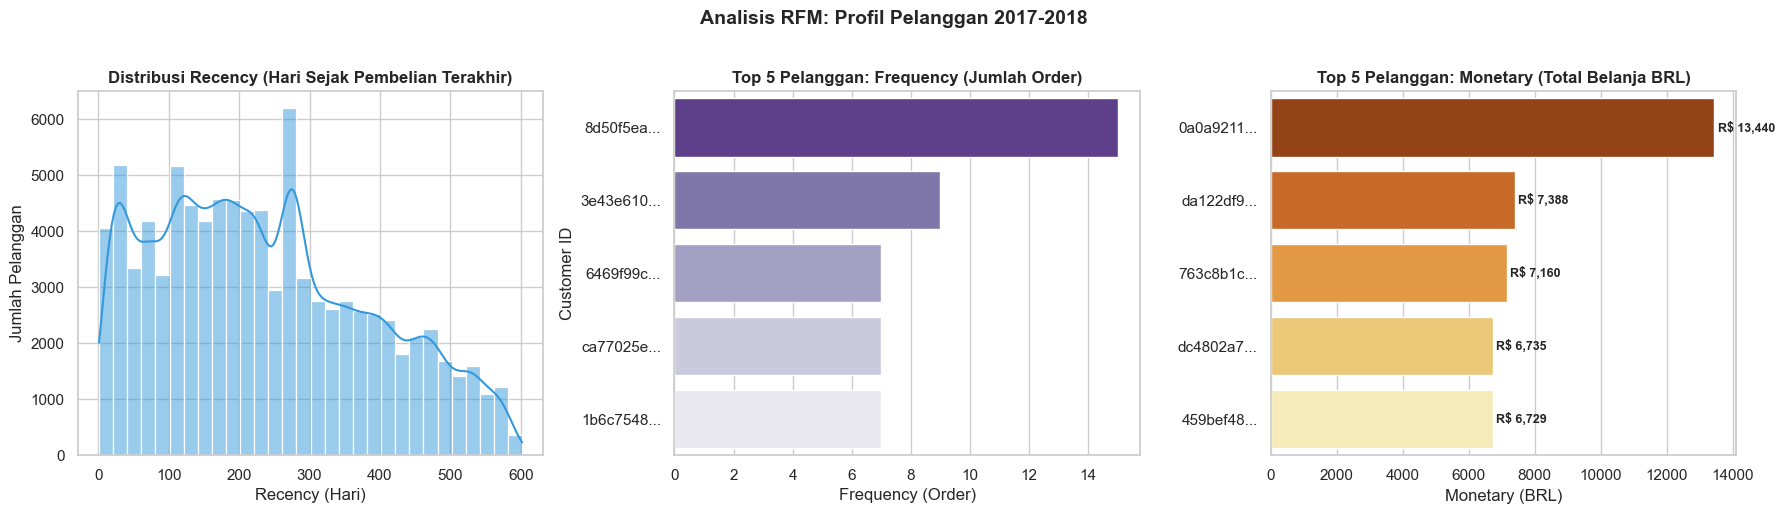

In [23]:
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))

# Distribusi Recency
sns.histplot(rfm_df['recency'], bins=30, kde=True, color='#3498db', ax=axes[0])
axes[0].set_title('Distribusi Recency (Hari Sejak Pembelian Terakhir)', fontweight='bold')
axes[0].set_xlabel('Recency (Hari)')
axes[0].set_ylabel('Jumlah Pelanggan')

# Top 5 Frequency
top_freq = rfm_df.sort_values(by='frequency', ascending=False).head(5)
sns.barplot(x=top_freq['frequency'], y=top_freq['customer_unique_id'].str[:8] + '...', palette='Purples_r', ax=axes[1])
axes[1].set_title('Top 5 Pelanggan: Frequency (Jumlah Order)', fontweight='bold')
axes[1].set_xlabel('Frequency (Order)')
axes[1].set_ylabel('Customer ID')

# Top 5 Monetary
top_mon = rfm_df.sort_values(by='monetary', ascending=False).head(5)
sns.barplot(x=top_mon['monetary'], y=top_mon['customer_unique_id'].str[:8] + '...', palette='YlOrBr_r', ax=axes[2])
axes[2].set_title('Top 5 Pelanggan: Monetary (Total Belanja BRL)', fontweight='bold')
axes[2].set_xlabel('Monetary (BRL)')
axes[2].set_ylabel('')

for i, v in enumerate(top_mon['monetary']):
    axes[2].text(v + 100, i, f'R$ {v:,.0f}', va='center', fontweight='bold', fontsize=9)

plt.suptitle('Analisis RFM: Profil Pelanggan 2017-2018', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

**Insight:**
- Distribusi recency menunjukkan bahwa sebagian besar pelanggan memiliki recency yang tinggi (rata-rata 237 hari), artinya mereka sudah lama tidak bertransaksi.
- Dari sisi frequency, sebagian besar pelanggan (97.0%) hanya melakukan 1 transaksi, sementara pelanggan paling aktif melakukan 15 transaksi.
- Distribusi monetary sangat skewed: tiga pelanggan teratas memiliki total belanja R$ 13,440.00, R$ 7,388.00, dan R$ 7,160.00, sementara median belanja keseluruhan hanya R$ 89.70.
- Profil ini menunjukkan bahwa program retensi perlu difokuskan pada peningkatan repeat purchase, karena mayoritas pelanggan bersifat one-time buyer.

### Pertanyaan 4: Geospatial Analysis — Sebaran Pelanggan per Negara Bagian
Tujuan: menganalisis distribusi pelanggan dan transaksi berdasarkan lokasi geografis (negara bagian di Brasil) untuk mengidentifikasi konsentrasi pasar.

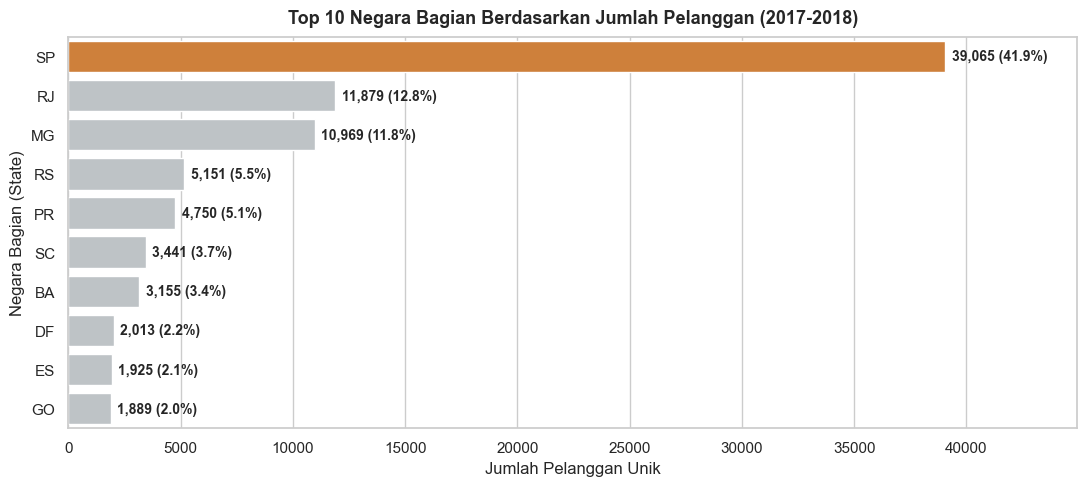

In [24]:
# Visualisasi Geospatial Sebaran Pelanggan (2017-2018)
plt.figure(figsize=(11, 5))

top_states = geo_summary.head(10)
palette = ['#e67e22' if state == 'SP' else '#bdc3c7' for state in top_states['customer_state']]

ax = sns.barplot(
    data=top_states,
    x='total_customers',
    y='customer_state',
    palette=palette
)

plt.title('Top 10 Negara Bagian Berdasarkan Jumlah Pelanggan (2017-2018)', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Jumlah Pelanggan Unik')
plt.ylabel('Negara Bagian (State)')

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f'{int(width):,} ({width / geo_summary["total_customers"].sum() * 100:.1f}%)',
                (width + 300, p.get_y() + p.get_height() / 2.),
                va='center', fontweight='bold', fontsize=10)

plt.xlim(0, top_states['total_customers'].max() * 1.15)
plt.tight_layout()
plt.show()

**Insight:**
- Visualisasi menegaskan dominasi São Paulo (SP) dengan 39,065 pelanggan unik (41.9% dari total), diikuti Rio de Janeiro (RJ) dan Minas Gerais (MG).
- Tiga negara bagian teratas (SP, RJ, MG) menguasai 66.5% total pelanggan, menunjukkan konsentrasi pasar yang sangat tinggi di wilayah tenggara Brasil.
- Dari sisi transaksi, SP juga memimpin dengan 40,406 pesanan dan total revenue R$ 5,055,587.13.
- Temuan ini menjadi dasar penentuan prioritas ekspansi logistik: fokus pada peningkatan kapasitas layanan di SP, RJ, dan MG.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Kategori **bed_bath_table** menghasilkan kuantitas pesanan terbanyak (10,945 pesanan) pada periode 2017-2018, sedangkan kategori **health_beauty** menghasilkan total revenue tertinggi (R$ 1,229,557.50). Perbedaan peringkat ini menunjukkan bahwa volume pesanan tidak selalu berbanding lurus dengan total pendapatan karena adanya variasi harga rata-rata antar kategori.

- **Conclusion pertanyaan 2:** Pesanan yang dikirim tepat waktu (On Time) memiliki rata-rata skor review 4.21, jauh lebih tinggi dibandingkan pesanan terlambat (Delayed) yang hanya 2.33. Proporsi bintang 5 pada pengiriman On Time (60.7%) juga jauh lebih tinggi daripada Delayed (18.6%). Data ini menunjukkan bahwa ketepatan waktu pengiriman berkaitan erat dengan tingkat kepuasan pelanggan.

- **Conclusion pertanyaan 3:** Dari 93,104 pelanggan unik, sebagian besar (97.0%) hanya bertransaksi satu kali dengan rata-rata frequency 1.03 dan rata-rata monetary R$ 141.57. Distribusi monetary yang sangat skewed (median R$ 89.70, maksimum R$ 13,440.00) menunjukkan bahwa sebagian kecil pelanggan berkontribusi pada total belanja yang jauh lebih tinggi. Profil ini mengindikasikan perlunya program retensi untuk meningkatkan repeat purchase.

- **Conclusion pertanyaan 4:** São Paulo (SP) menjadi negara bagian dengan konsentrasi pelanggan terbesar (39,065 pelanggan, 41.9% dari total) sekaligus total transaksi tertinggi (40,406 pesanan, revenue R$ 5,055,587.13). Tiga negara bagian teratas (SP, RJ, MG) menguasai 66.5% total pelanggan, menunjukkan konsentrasi pasar yang sangat tinggi di wilayah tenggara Brasil.

**Rekomendasi Action Item:**
- Fokuskan stok dan promosi utama pada kategori **bed_bath_table** (volume tertinggi) dan **health_beauty** (revenue tertinggi) untuk memaksimalkan penjualan dan pendapatan.
- Evaluasi dan tingkatkan kinerja mitra logistik untuk menekan angka keterlambatan pengiriman, mengingat pesanan Delayed berkaitan erat dengan rating rendah (rata-rata 2.33 vs 4.21 untuk On Time).
- Rancang program retensi pelanggan (seperti loyalty points, diskon repeat order, atau email follow-up) yang difokuskan pada pelanggan one-time buyer (97.0% dari total) untuk meningkatkan frequency pembelian.
- Prioritaskan ekspansi kapasitas logistik di negara bagian SP, RJ, dan MG yang menguasai 66.5% total pelanggan, untuk memastikan kecepatan dan kapasitas pengiriman memadai.

In [25]:
# Ekspor dataset yang sudah dirapikan untuk aplikasi Streamlit
dashboard_dir = 'dashboard'
os.makedirs(dashboard_dir, exist_ok=True)

dashboard_df = all_df[[
    'order_id',
    'customer_id',
    'customer_unique_id',
    'customer_city',
    'customer_state',
    'order_purchase_timestamp',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
    'delivery_status',
    'product_category_name_english',
    'price',
    'freight_value',
    'review_score'
]]

out_csv = os.path.join(dashboard_dir, 'main_data.csv')
dashboard_df.to_csv(out_csv, index=False)

print('Export berhasil ke:', out_csv)
print('Ukuran baris dan kolom:', dashboard_df.shape)

Export berhasil ke: dashboard\main_data.csv
Ukuran baris dan kolom: (110197, 13)
